In [44]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import pandas as pd
from tensorflow import keras
from datetime import datetime, timedelta

In [10]:
start = '2012-01-01'
end = '2025-04-06' #datetime.date.today().strftime('%Y-%m-%d')
stock = 'AAPL'

data = yf.download(stock, start, end)

# client = RESTClient("qtp5Ybu7plDZOW7pZV_tKgeelkg3HCY8")

# # Define date range
# start_date = "2012-01-01"
# end_date = datetime.now().strftime("%Y-%m-%d")

# try:
#     # Get daily bars for AAPL
#     bars = client.get_aggs(
#         ticker="AAPL",
#         multiplier=1,
#         timespan="day",
#         from_=start_date,
#         to=end_date
#     )
    
#     # Convert to DataFrame
#     data = pd.DataFrame([bar.__dict__ for bar in bars])
#     # Convert timestamp to datetime
#     data['datetime'] = pd.to_datetime(data['timestamp'], unit='ms')
#     data = data.set_index('datetime')

    
    
#     print(data.head())
# except Exception as e:
#     print(f"Error with Polygon.io: {e}")

[*********************100%***********************]  1 of 1 completed


In [11]:
data.reset_index(inplace=True)


In [12]:
data

Price,Date,Close,High,Low,Open,Volume
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL
0,2012-01-03,12.375389,12.413608,12.308281,12.320319,302220800
1,2012-01-04,12.441897,12.479214,12.316708,12.338375,260022000
2,2012-01-05,12.580026,12.595674,12.418724,12.487338,271269600
3,2012-01-06,12.711537,12.722070,12.615840,12.632391,318292800
4,2012-01-09,12.691371,12.872535,12.679935,12.804824,394024400
...,...,...,...,...,...,...
3329,2025-03-31,222.130005,225.619995,216.229996,217.009995,65299300
3330,2025-04-01,223.190002,223.679993,218.899994,219.809998,36412700
3331,2025-04-02,223.889999,225.190002,221.020004,221.320007,35905900


In [13]:
ma_100_days = data.Close.rolling(100).mean()
ma_100_days

Ticker,AAPL
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
3329,234.514269
3330,234.530945
3331,234.540252
3332,234.349843


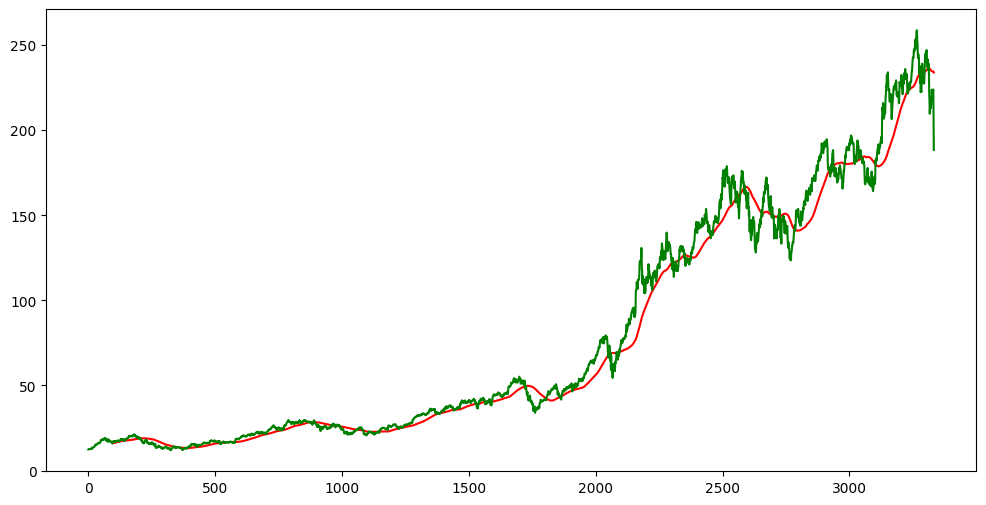

In [14]:
plt.figure(figsize=(12,6))
plt.plot(ma_100_days, 'r')
plt.plot(data.Close, 'g')
plt.show()

In [15]:
ma_200_days = data.Close.rolling(200).mean()
ma_200_days

Ticker,AAPL
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
3329,228.708341
3330,228.762510
3331,228.814348
3332,228.771407


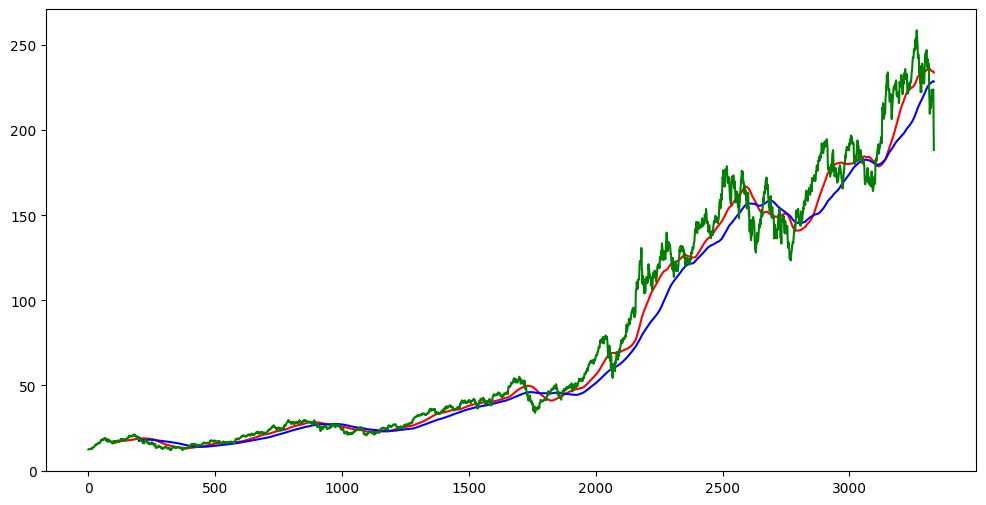

In [16]:
plt.figure(figsize=(12,6))
plt.plot(ma_100_days, 'r')
plt.plot(ma_200_days,'b')
plt.plot(data.Close,'g')
plt.show()

In [17]:
data_train = pd.DataFrame(data['Close'][0: int(len(data)*0.80)])
data_test = pd.DataFrame(data['Close'][int(len(data)*0.80): len(data)])

print(data_train.shape, data_test.shape)

(2667, 1) (667, 1)


In [18]:
data_train.head()

Ticker,AAPL
0,12.375389
1,12.441897
2,12.580026
3,12.711537
4,12.691371


In [19]:
data_test.tail()

Ticker,AAPL
3329,222.130005
3330,223.190002
3331,223.889999
3332,203.190002
3333,188.380005


In [20]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [21]:
data_train_scale = scaler.fit_transform(data_train)
data_train_scale

array([[0.00269216],
       [0.00309052],
       [0.00391787],
       ...,
       [0.90731541],
       [0.90595619],
       [0.90311873]])

In [22]:
data_train_scale.shape

(2667, 1)

In [23]:
x = []
y = []

for i in range(100, data_train_scale.shape[0]):
    x.append(data_train_scale[i-100:i])
    y.append(data_train_scale[i,0])


In [24]:
x, y = np.array(x), np.array(y)

In [ ]:
from keras.layers import Dense, Dropout, LSTM
from keras.models import Sequential

In [26]:
model = Sequential()
model.add(LSTM(units = 50, activation = 'relu', return_sequences = True, input_shape = (x.shape[1], 1)))
model.add(Dropout(0.2))

model.add(LSTM(units = 60, activation='relu', return_sequences = True))
model.add(Dropout(0.3))

model.add(LSTM(units = 80, activation = 'relu', return_sequences = True))
model.add(Dropout(0.4))

model.add(LSTM(units = 120, activation = 'relu'))
model.add(Dropout(0.5))

model.add(Dense(units =1))

d:\Project OF BE\Stock_Model\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


AttributeError: module 'ml_dtypes' has no attribute 'float4_e2m1fn'


model.summary()

In [27]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [30]:
model.fit(x,y, epochs = 50, batch_size = 128, verbose =1)

Epoch 1/50


21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 338ms/step - loss: 0.0028
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 324ms/step - loss: 0.0023
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 316ms/step - loss: 0.0025
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 327ms/step - loss: 0.0026
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 331ms/step - loss: 0.0029
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 310ms/step - loss: 0.0024
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 322ms/step - loss: 0.0024
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 322ms/step - loss: 0.0024
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 310ms/step - loss: 0.0025
Epoch 10/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 305ms/step - loss: 0.0028
Epoch 11/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 316ms/step - loss: 0.0020
Epoch 12/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 302ms/step - loss: 0.0023
Epoch 13/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 322ms/step - loss: 0.0023
Epoch 14/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 307ms/step - loss: 0.0021
Epoch 15/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 316ms/step - loss: 0.0025

In [31]:
model.save('stock_prediction_model.h5')

In [32]:
pas_100_days = data_train.tail(100)

In [33]:
data_test = pd.concat([pas_100_days, data_test], ignore_index=True)
data_test.head()

Ticker,AAPL
0,157.045303
1,158.058899
2,161.365311
3,162.743011
4,166.128159


In [34]:
data_test_scale  =  scaler.fit_transform(data_test)
data_test_scale.shape

(767, 1)

In [35]:
x_t = []
y_t = []

for i in range(100, data_test_scale.shape[0]):
    x_t.append(data_test_scale[i-100:i])
    y_t.append(data_test_scale[i,0])
x_t, y_t = np.array(x_t), np.array(y_t)
print(x_t.shape, y_t.shape)

(667, 100, 1) (667,)


In [36]:
y_predict = model.predict(x_t)
y_predict

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step


array([[0.17940287],
       [0.18862778],
       [0.19869974],
       [0.20946473],
       [0.22058211],
       [0.23206553],
       [0.24367884],
       [0.25524327],
       [0.26657832],
       [0.2774127 ],
       [0.287349  ],
       [0.29603207],
       [0.30324224],
       [0.30898675],
       [0.3131965 ],
       [0.31578535],
       [0.31666002],
       [0.3157854 ],
       [0.3132949 ],
       [0.30939013],
       [0.30431426],
       [0.29835743],
       [0.29183018],
       [0.285065  ],
       [0.27845046],
       [0.27216902],
       [0.26632366],
       [0.26092345],
       [0.25593197],
       [0.25134423],
       [0.24719474],
       [0.2434807 ],
       [0.24016654],
       [0.23710877],
       [0.23410115],
       [0.23105441],
       [0.22792429],
       [0.22450753],
       [0.22056527],
       [0.2160837 ],
       [0.2111734 ],
       [0.20614606],
       [0.20106408],
       [0.19610748],
       [0.19130324],
       [0.1868072 ],
       [0.18273945],
       [0.179

In [37]:
y_t

array([2.89831521e-01, 3.21375954e-01, 3.15899258e-01, 3.42259068e-01,
       3.50218449e-01, 3.49049927e-01, 3.60148961e-01, 3.57228109e-01,
       3.38024053e-01, 3.09181445e-01, 3.06698986e-01, 3.08889484e-01,
       3.27144385e-01, 2.80339063e-01, 2.63982925e-01, 2.45947164e-01,
       2.33606788e-01, 2.39010437e-01, 2.23311268e-01, 2.13964790e-01,
       2.24406291e-01, 2.13453576e-01, 2.34702263e-01, 2.78951515e-01,
       2.08926374e-01, 2.19659949e-01, 1.98192574e-01, 1.85998404e-01,
       2.13599670e-01, 2.31270084e-01, 2.08050266e-01, 2.00894512e-01,
       1.84026821e-01, 1.86509505e-01, 1.93738419e-01, 1.79718646e-01,
       1.25976936e-01, 9.47249162e-02, 1.25757683e-01, 1.52409680e-01,
       1.54600178e-01, 1.47517471e-01, 1.08525210e-01, 1.10934848e-01,
       1.00420075e-01, 9.57471184e-02, 1.29700963e-01, 9.60391923e-02,
       1.25465722e-01, 1.35250254e-01, 1.36053768e-01, 1.32621589e-01,
       1.60952870e-01, 1.76871180e-01, 1.97973547e-01, 1.76140938e-01,
      

In [38]:
scaler.scale_

array([0.00739905])

In [39]:
scale_factor = 1/scaler.scale_

In [40]:
y_predict = y_predict*scale_factor

In [41]:
y_t = y_t * scale_factor

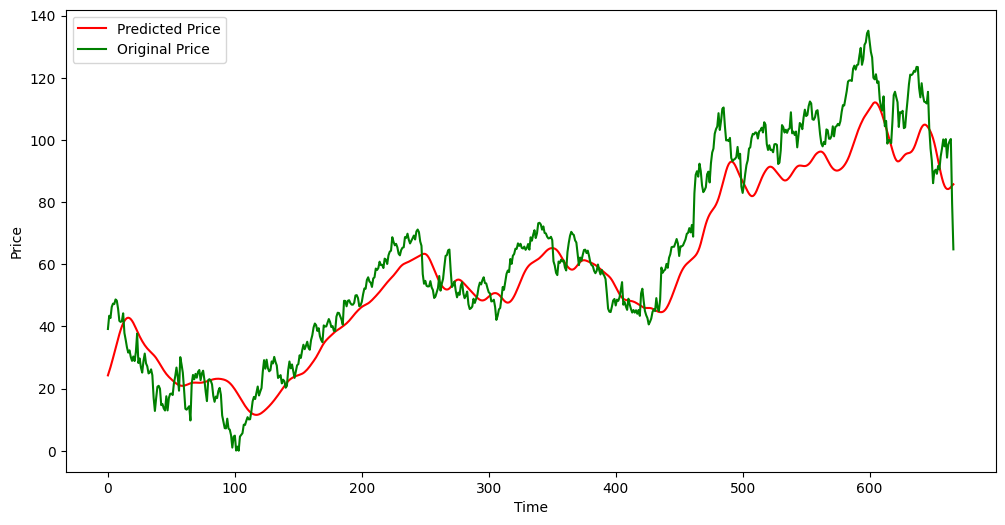

In [42]:
plt.figure(figsize=(12,6))
plt.plot(y_predict, 'r', label = 'Predicted Price')
plt.plot(y_t, 'g', label = 'Original Price')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

In [43]:
model.save('Stock Predictions Model.keras')